# Evaluation: which strawberry model should we trust?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/03_Evaluation/notebooks/TD2_strawberry_solution.ipynb)

In TD1 (Foundations), you used eight infrared features to predict Strawberry
or NON-Strawberry. Here we compare a small tree, a deep tree and a random
forest: does a better training result also mean better predictions?

Section 1 is a quick recap. Run its four setup cells, then focus on the new
training–validation–test split in section 2. All code is supplied; answer
the interpretation questions in the Your answer text cells.

Instructor copy: suggested answers are included.

## 1. Quick recap and setup

We reuse the same fruit-purée data, labels and preparation as TD1:
exclude the two conflicting records and turn each spectrum into
eight window means (B1–B8). Strawberry and NON-Strawberry remain
the two classes. The code below prepares these familiar inputs.

Load the tools for tables, plots and the three models.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier

Read the same fixed data file, separate the labels, and arrange
the measured spectra with one sample per row, as in TD1.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/zwbben/SpectroscopyData/"
    "4db9b8168fac1185973d1e7888d51f7f33f94857/MIR_Fruit_purees.csv"
)
raw_data = pd.read_csv(DATA_URL, header=None)
labels = raw_data.iloc[0, 1:]
numeric_data = raw_data.iloc[1:].astype(float)
spectra = numeric_data.iloc[:, 1:].T
spectra.columns = numeric_data.iloc[:, 0]

Leave out the same two identically measured but differently labelled
records. This keeps the same 981 samples as TD1.

In [3]:
repeated = spectra.duplicated(keep=False)
spectra = spectra.loc[~repeated]
labels = labels.loc[~repeated]

Calculate the same eight window means. The table is a reminder of
the model inputs; we keep these features fixed when comparing models.

In [4]:
features = pd.DataFrame(index=spectra.index)
features["B1"] = spectra.loc[:, 899:1012].mean(axis=1)
features["B2"] = spectra.loc[:, 1012:1125].mean(axis=1)
features["B3"] = spectra.loc[:, 1125:1238].mean(axis=1)
features["B4"] = spectra.loc[:, 1238:1351].mean(axis=1)
features["B5"] = spectra.loc[:, 1351:1464].mean(axis=1)
features["B6"] = spectra.loc[:, 1464:1577].mean(axis=1)
features["B7"] = spectra.loc[:, 1577:1690].mean(axis=1)
features["B8"] = spectra.loc[:, 1690:1803].mean(axis=1)
features.head().round(4)

,B1,B2,B3,B4,B5,B6,B7,B8
1,0.0035,0.0097,0.0052,0.0051,0.0049,0.0019,0.0020,0.0019
2,0.0046,0.0149,0.0052,0.0043,0.0047,0.0006,-0.0003,0.0002
3,0.0041,0.0098,0.0050,0.0048,0.0047,0.0019,0.0022,0.0017
4,0.0037,0.0107,0.0055,0.0052,0.0045,0.0009,0.0015,0.0022
5,0.0038,0.0104,0.0057,0.0053,0.0044,0.0008,0.0012,0.0024


## 2. Give three sets of samples different jobs

- Training: teach each model.
- Validation: compare models and choose one.
- Test: check the chosen model after the choice is fixed.

Keep TD1's 197 test samples aside. Divide its original 784 training samples
into 588 training and 196 validation samples. Every model uses exactly the
same groups, giving about 60% training, 20% validation and 20% test samples.
The small tree now learns from fewer examples than in TD1, so its results
can change.

The code first repeats TD1's split, then sets aside a quarter of the original
training group for validation. `X_development` and `y_development` hold that
original group before it is divided.

In [5]:
X_development, X_test, y_development, y_test = train_test_split(
    features, labels, test_size=0.20, random_state=42, stratify=labels
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_development, y_development, test_size=0.25,
    random_state=42, stratify=y_development
)
print("Training:", len(X_train))
print("Validation:", len(X_validation))
print("Test:", len(X_test))

Training: 588
Validation: 196
Test: 197


The test group is the same one used in Foundations. We keep it out of model
comparison here, but its reuse is a classroom exercise rather than new
independent evidence. The file also lacks IDs for physical specimens and batches.

### Stop and explain 1

Which samples teach the models, which help us choose, and which are used
at the end? Why should all models use the same training and validation samples?

Suggested answer: Training samples teach each model; validation samples
compare them; test samples check the fixed choice. Using the same groups
makes the comparison fairer because a score difference is not simply caused
by one model receiving easier validation samples.

## 3. Compare a small and a deep tree

Start with a tree that asks at most two questions along a path. `fit`
learns from the training data. For these classifiers, `score` gives
accuracy on the named data: the fraction of predictions matching the labels.
The two scores below answer different questions: how well does it fit the
training examples, and how well does it predict validation examples?

An accuracy of 0.90 means that 90% of the samples were classified correctly.

In [6]:
small_tree = DecisionTreeClassifier(max_depth=2, random_state=42)
small_tree.fit(X_train, y_train)
small_training = small_tree.score(X_train, y_train)
small_validation = small_tree.score(X_validation, y_validation)
print("Small tree, training:", round(small_training, 3))
print("Small tree, validation:", round(small_validation, 3))

Small tree, training: 0.838
Small tree, validation: 0.827


Now remove the depth limit. The deep tree can keep adding questions to
separate training examples. Only the model's complexity changes; the
measurements, labels and sample groups stay the same.

Overfitting means learning details that help on the training samples
but do not help as much on other samples. A growing gap between
training and validation accuracy is a warning sign.

In [7]:
deep_tree = DecisionTreeClassifier(random_state=42)
deep_tree.fit(X_train, y_train)
deep_training = deep_tree.score(X_train, y_train)
deep_validation = deep_tree.score(X_validation, y_validation)
print("Deep tree, training:", round(deep_training, 3))
print("Deep tree, validation:", round(deep_validation, 3))

Deep tree, training: 1.0
Deep tree, validation: 0.842


### Stop and explain 2

How much does training accuracy improve when the tree becomes deeper?
Does validation accuracy improve by as much? Explain what this suggests
about overfitting.

Suggested answer for the saved run: The small tree has 83.8%
training accuracy and 82.7% validation accuracy. The deep
tree reaches 100.0% training accuracy but only 84.2%
validation accuracy. Its training advantage does not transfer by the same
amount to excluded examples. This growing gap is evidence of overfitting;
a higher training score alone is not a reason to prefer the deeper tree.

## 4. Add a random forest

A random forest combines many trees instead of relying on one. Here it uses
100 trees. The code follows exactly the same steps: create, fit, then score
on training and validation samples.

In [8]:
forest = RandomForestClassifier(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)
forest_training = forest.score(X_train, y_train)
forest_validation = forest.score(X_validation, y_validation)
print("Forest, training:", round(forest_training, 3))
print("Forest, validation:", round(forest_validation, 3))

Forest, training: 1.0
Forest, validation: 0.898


Put the three pairs of scores in one table. Look especially at validation
accuracy: these samples were excluded from every model's training.

In [9]:
results = pd.DataFrame({
    "Model": ["Small tree", "Deep tree", "Forest"],
    "Training": [small_training, deep_training, forest_training],
    "Validation": [small_validation, deep_validation, forest_validation]
})
results = results.set_index("Model")
results.round(3)

,Training,Validation
Model,,
Small tree,0.838,0.827
Deep tree,1.000,0.842
Forest,1.000,0.898


The bars show the same numbers. A large gap between a model's training and
validation bars is a warning. Also compare with a simple rule that always
predicts NON-Strawberry, the most common training class.

A forest can also fit its training samples very closely. Its validation
accuracy still needs to be checked; combining trees does not remove that need.

In the comparison rule, `==` checks whether a label matches NON-Strawberry;
`mean()` gives the fraction of matching labels.

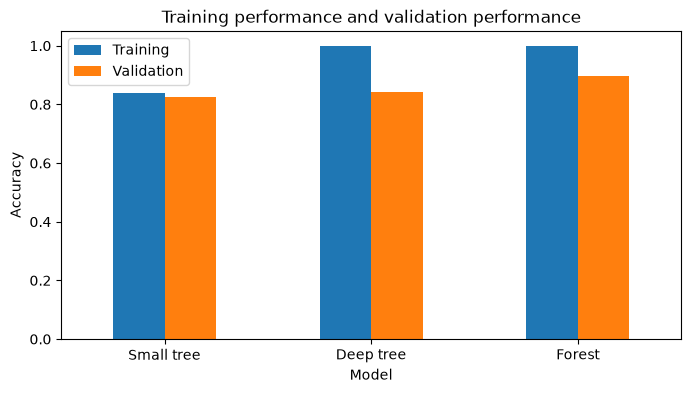

Always NON-Strawberry, validation: 0.643


In [10]:
results.plot.bar(figsize=(8, 4), rot=0)
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.title("Training performance and validation performance")
plt.show()
baseline_validation = (y_validation == "NON-Strawberry").mean()
print("Always NON-Strawberry, validation:", round(baseline_validation, 3))

### Stop and explain 3

Which model has the highest validation accuracy? Does it beat the constant
NON-Strawberry rule? Explain why the training score alone cannot choose the winner.

Suggested answer for the saved run: Forest has the highest validation
accuracy, 89.8%, compared with 64.3% for
always predicting NON-Strawberry. A model can fit training details that do
not help elsewhere. The validation scores are the relevant comparison here,
although one split cannot prove that the ranking will always be the same.

## 5. Choose first, then test

Choose the model with the highest validation accuracy. `idxmax` returns
the name beside the largest validation number. The first line links each
name to its trained model; `models[chosen_name]` retrieves that model.
No model is retrained here.

In [11]:
models = {"Small tree": small_tree, "Deep tree": deep_tree, "Forest": forest}
chosen_name = results["Validation"].idxmax()
chosen_model = models[chosen_name]
print("Chosen using validation samples:", chosen_name)

Chosen using validation samples: Forest


Now apply that fixed model to the test features. The reference test labels
are used only to check the predictions. Keep the choice fixed after this
point; changing models to improve the test score would turn testing into
another round of model selection.

In the confusion matrix, rows are reference labels and columns are predictions.
The diagonal contains correct predictions. A NON-Strawberry sample predicted
Strawberry is a false acceptance; the opposite error is a false rejection.

Test accuracy: 0.944


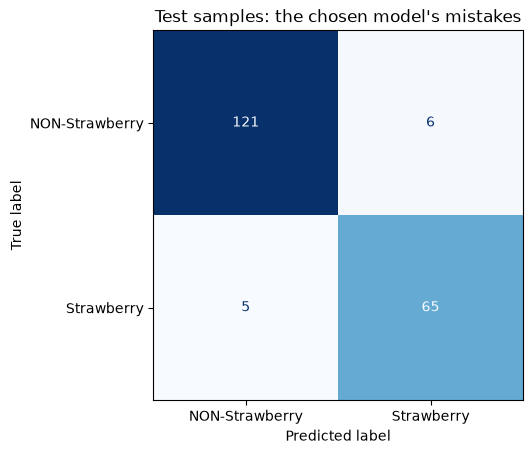

In [12]:
predictions = chosen_model.predict(X_test)
test_accuracy = accuracy_score(y_test, predictions)
print("Test accuracy:", round(test_accuracy, 3))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=["NON-Strawberry", "Strawberry"],
    cmap="Blues", colorbar=False
)
plt.title("Test samples: the chosen model's mistakes")
plt.show()

### Stop and explain 4

How many false acceptances and false rejections occurred? Why would it be
misleading to try different settings now and report only the best test score?

Suggested answer for the saved run: There are 6 false
acceptances and 5 false rejections, with 94.4%
overall test accuracy. Trying settings after seeing these results uses test
information to choose the model. Reporting only the best attempt would
hide the unsuccessful attempts and make the result look too favourable.

## 6. Explain the comparison

Training teaches a model; validation helps choose between models;
testing checks the fixed choice. A large training/validation gap warns
about overfitting. One split and one dataset cannot establish how the
model will perform on every future supplier or adulterant.

Next, Applications keeps the same eight features and test group but
changes the question: which measurements are unusual compared with
the labelled Strawberry training samples?

### Stop and explain 5

Write three sentences for the laboratory manager: what the small-versus-deep
comparison showed, which model was chosen and how it performed on testing,
and one limitation before using it on new products.

Example: The deep tree fitted its training samples better than the small
tree, but the validation improvement was smaller, showing overfitting.
Forest was selected using validation samples and classified
94.4% of the 197 test samples correctly. New products still need
independent checks because the dataset does not document suppliers and
specimen groups, and this classroom test group was already seen in Foundations.

## Data and reuse

The dataset contains measured infrared spectra of fruit purées. The
original file has 983 spectra; 981 remain after excluding the conflicting
pair. NON-Strawberry includes other fruits and adulterated mixtures.
The file does not give separate adulterant, supplier or replicate IDs.
These exercises cannot establish product purity or identify an adulterant.

- Holland, Kemsley and Wilson (1998), *Use of Fourier transform infrared
  spectroscopy and partial least squares regression for the detection of
  adulteration of strawberry purées*.
  [Original study](https://research-portal.uea.ac.uk/en/publications/use-of-fourier-transform-infrared-spectroscopy-and-partial-least-/).
- Shu, Tang, Zhang and Zheng (2019),
  [dataset deposition](https://doi.org/10.17632/frrv2yd9rg.1), version 1.
  Data licence: [CC BY-NC 3.0](https://creativecommons.org/licenses/by-nc/3.0/).
  The data licence is separate from the course-code licence.

The fixed spectral windows are teaching summaries, not selected chemical
markers. This exercise does not reproduce the original paper's analysis.